# Fit a tree, plot it, change its depth

A bank in Taiwan recorded 30,000 credit-card clients in 2005. One row is one client; `default` is 1 when the client defaulted the next month. We type each cell together and stop at each checkpoint.

## Step 1 · Run the starter

The cell loads the file with readable column names (`PAY_0` is the September repayment status, `PAY_2` August, and so on), splits it 80 / 20 with `stratify=y, random_state=42`, and prints the training and test rows and the accuracy of a model that always says "no default".

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

NAMES = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
         + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)])

df = pd.read_csv("data/credit_default.csv")
df = df.drop(columns=[c for c in df.columns if c.upper() == "ID"])
target = [c for c in df.columns if c.lower() in ("y", "default", "default.payment.next.month",
                                                 "default payment next month")][0]
y = df.pop(target).astype(int).rename("default")
if list(df.columns[:2]) == ["X1", "X2"]:            # the UCI download names the columns X1 ... X23
    df.columns = NAMES
X = df.rename(columns={"PAY_1": "PAY_0"})[NAMES]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(len(X_train), "training clients,", len(X_test), "test clients")
print("dummy accuracy", round(accuracy_score(y_test, dummy.predict(X_test)), 3))

24000 training clients, 6000 test clients
dummy accuracy 0.779


## Step 2 · A tree of depth 2, drawn

Fit `DecisionTreeClassifier(max_depth=2, random_state=42)` and draw it with `plot_tree(tree, feature_names=X.columns, filled=True)`. Read the root: which column, which threshold?

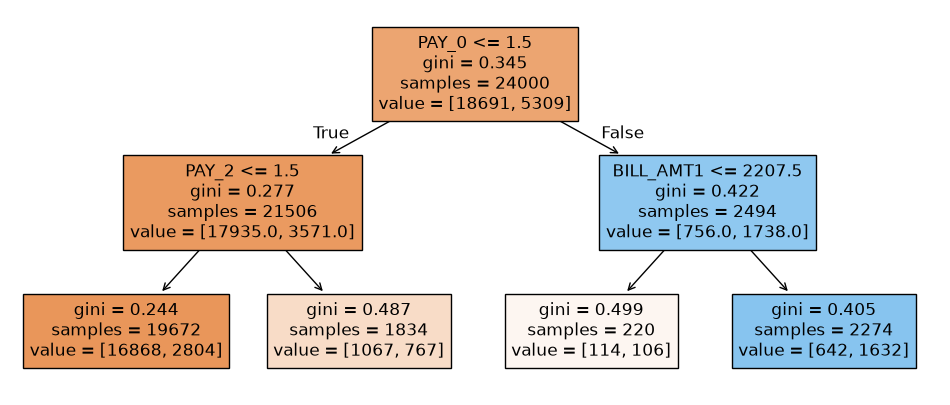

root: PAY_0 <= 1.5


In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(12, 5))
plot_tree(tree, feature_names=X.columns, filled=True)
plt.show()
root = f"{X.columns[tree.tree_.feature[0]]} <= {tree.tree_.threshold[0]:g}"
print("root:", root)

## Step 3 · Three numbers

Print training and test accuracy, and the test ROC AUC from `predict_proba(X_test)[:, 1]`.

In [3]:
def three_numbers(t):
    return (round(accuracy_score(y_train, t.predict(X_train)), 3), round(accuracy_score(y_test, t.predict(X_test)), 3),
            round(roc_auc_score(y_test, t.predict_proba(X_test)[:, 1]), 3))


d2 = three_numbers(tree)
print("train accuracy, test accuracy, test AUC:", d2)

train accuracy, test accuracy, test AUC: (0.82, 0.817, 0.69)


## Step 4 · Let it grow

Change `max_depth` to 5, then remove it (`max_depth=None`). Print the same three numbers each time, plus `tree.get_n_leaves()` and `tree.get_depth()`.

In [4]:
grown = {}
for depth in (5, None):
    t = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    grown[depth] = t
    print(f"max_depth={depth}: {three_numbers(t)}, {t.get_n_leaves()} leaves, depth {t.get_depth()}")

max_depth=5: (0.825, 0.817, 0.742), 31 leaves, depth 5


max_depth=None: (0.999, 0.715, 0.607), 3791 leaves, depth 41


## Bonus · Does a tree care about units?

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

scaled = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=5, random_state=42)).fit(X_train, y_train)
print("depth 5, scaled: test accuracy", round(accuracy_score(y_test, scaled.predict(X_test)), 3))

depth 5, scaled: test accuracy 0.817


## Check yourself

In [6]:
d5, full = three_numbers(grown[5]), three_numbers(grown[None])
check = {
    "Step 1 · training clients": len(X_train),
    "Step 1 · test clients": len(X_test),
    "Step 1 · dummy accuracy": round(accuracy_score(y_test, dummy.predict(X_test)), 3),
    "Step 2 · root column": X.columns[tree.tree_.feature[0]],
    "Step 2 · root threshold": round(tree.tree_.threshold[0], 2),
    "Step 3 · depth 2 train accuracy": d2[0],
    "Step 3 · depth 2 test accuracy": d2[1],
    "Step 3 · depth 2 test AUC": d2[2],
    "Step 4 · depth 5 train accuracy": d5[0],
    "Step 4 · depth 5 test accuracy": d5[1],
    "Step 4 · depth 5 test AUC": d5[2],
    "Step 4 · depth 5 leaves": grown[5].get_n_leaves(),
    "Step 4 · no limit train accuracy": full[0],
    "Step 4 · no limit test accuracy": full[1],
    "Step 4 · no limit test AUC": full[2],
    "Step 4 · no limit leaves": grown[None].get_n_leaves(),
    "Step 4 · no limit depth": grown[None].get_depth(),
    "Bonus · depth 5 scaled test accuracy": round(accuracy_score(y_test, scaled.predict(X_test)), 3),
}
for label, value in check.items():
    print(f"{label:<38} {value}")

Step 1 · training clients              24000
Step 1 · test clients                  6000
Step 1 · dummy accuracy                0.779
Step 2 · root column                   PAY_0
Step 2 · root threshold                1.5
Step 3 · depth 2 train accuracy        0.82
Step 3 · depth 2 test accuracy         0.817
Step 3 · depth 2 test AUC              0.69
Step 4 · depth 5 train accuracy        0.825
Step 4 · depth 5 test accuracy         0.817
Step 4 · depth 5 test AUC              0.742
Step 4 · depth 5 leaves                31
Step 4 · no limit train accuracy       0.999
Step 4 · no limit test accuracy        0.715
Step 4 · no limit test AUC             0.607
Step 4 · no limit leaves               3791
Step 4 · no limit depth                41
Bonus · depth 5 scaled test accuracy   0.817
